## 0. Setup e imports

In [1]:
import os
import time
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms, models
from torchvision.datasets import ImageFolder
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch : {torch.__version__}")
print(f"Device  : {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU     : {torch.cuda.get_device_name(0)}")

PyTorch : 2.11.0+cu130
Device  : cuda
GPU     : Tesla T4


## 1. Configuración del proyecto

Las 34 clases seleccionadas (comidas populares, con contraste nutricional) y los hiperparámetros base.

In [2]:
CLASSES = [
    "hamburger", "pizza", "hot_dog", "french_fries", "club_sandwich",
    "grilled_cheese_sandwich", "nachos", "onion_rings", "steak", "fried_rice",
    "spaghetti_bolognese", "spaghetti_carbonara", "lasagna", "grilled_salmon",
    "tacos", "sushi", "ramen", "pad_thai", "dumplings", "chicken_curry",
    "chicken_wings", "pancakes", "waffles", "french_toast", "omelette",
    "caesar_salad", "greek_salad", "guacamole", "ice_cream", "donuts",
    "cheesecake", "hot_and_sour_soup", "miso_soup", "french_onion_soup",
]
NUM_CLASSES = len(CLASSES)

IMG_SIZE   = 224      # EfficientNet-B0 espera 224x224
BATCH_SIZE = 64
EPOCHS     = 8
LR         = 1e-3     # para la cabeza; el backbone usa un lr menor
VAL_FRAC   = 0.15     # fracción del train que se usa como validación

print(f"Clases: {NUM_CLASSES}")
print(CLASSES)

Clases: 34
['hamburger', 'pizza', 'hot_dog', 'french_fries', 'club_sandwich', 'grilled_cheese_sandwich', 'nachos', 'onion_rings', 'steak', 'fried_rice', 'spaghetti_bolognese', 'spaghetti_carbonara', 'lasagna', 'grilled_salmon', 'tacos', 'sushi', 'ramen', 'pad_thai', 'dumplings', 'chicken_curry', 'chicken_wings', 'pancakes', 'waffles', 'french_toast', 'omelette', 'caesar_salad', 'greek_salad', 'guacamole', 'ice_cream', 'donuts', 'cheesecake', 'hot_and_sour_soup', 'miso_soup', 'french_onion_soup']


## 2. Localizar el dataset Food-101

**Dataset a usar en Kaggle:** `kmader/food41` (Food-101 completo: 101 clases, 101.000 imágenes, carpetas por clase con nombre en `snake_case`, igual que nuestras 34). Es el más popular y estándar en Kaggle.

- *Add Input → busca "food41" (kmader)* y añádelo. Queda montado típicamente en `/kaggle/input/food41/images/<clase>/`.
- La celda prueba primero esa ruta conocida; si no está, la detecta automáticamente; y como último recurso descarga con torchvision.

In [3]:
def find_images_root(base="/kaggle/input"):
    """Busca la carpeta que contiene subcarpetas con los nombres de las clases de Food-101."""
    base = Path(base)
    if not base.exists():
        return None
    # buscamos una carpeta 'images' tipica de Food-101, o una que tenga al menos
    # algunas de nuestras clases como subcarpetas
    candidatos = list(base.rglob("images")) + list(base.rglob("*"))
    for c in candidatos:
        if c.is_dir():
            subdirs = {p.name for p in c.iterdir() if p.is_dir()}
            if len(set(CLASSES) & subdirs) >= 5:   # encontro varias de nuestras clases
                return c
    return None

# 1) Ruta conocida del dataset kmader/food41 en Kaggle
RUTAS_CONOCIDAS = [
    "/kaggle/input/food41/images",
    "/kaggle/input/food-101/food-101/images",
]
IMAGES_ROOT = next((Path(r) for r in RUTAS_CONOCIDAS if Path(r).is_dir()), None)

# 2) Si no, detección automática en /kaggle/input
if IMAGES_ROOT is None:
    IMAGES_ROOT = find_images_root()

# 3) Último recurso: descargar con torchvision
if IMAGES_ROOT is not None:
    print(f"Dataset encontrado en: {IMAGES_ROOT}")
else:
    print("No se encontro Food-101 en /kaggle/input. Descargando con torchvision...")
    from torchvision.datasets import Food101
    Food101(root="/kaggle/working/food101", split="train", download=True)
    Food101(root="/kaggle/working/food101", split="test",  download=True)
    IMAGES_ROOT = Path("/kaggle/working/food101/food-101/images")
    print(f"Dataset en: {IMAGES_ROOT}")

Dataset encontrado en: /kaggle/input/datasets/kmader/food41/images


## 3. Construir el dataset filtrado a 34 clases

`ImageFolder` carga todas las carpetas; nos quedamos solo con las 34 clases elegidas re-mapeando los índices.

In [4]:
# Verificar que las 34 clases existen como carpetas
disponibles = {p.name for p in IMAGES_ROOT.iterdir() if p.is_dir()}
faltantes = [c for c in CLASSES if c not in disponibles]
if faltantes:
    print("ATENCION, clases no encontradas como carpeta:", faltantes)
    print("Revisa los nombres en el dataset de Kaggle (pueden variar).")
else:
    print("Las 34 clases estan presentes.")

class_to_idx = {c: i for i, c in enumerate(CLASSES)}

# Dataset base sin transform (lo aplicamos despues por split)
full = ImageFolder(str(IMAGES_ROOT))

# indices de las muestras cuyas clases estan en nuestras 34
keep_names = set(CLASSES)
idx_de_clase_full_a_nombre = {v: k for k, v in full.class_to_idx.items()}
indices = [i for i, (_, y) in enumerate(full.samples)
           if idx_de_clase_full_a_nombre[y] in keep_names]
print(f"Muestras totales (34 clases): {len(indices):,}")

Las 34 clases estan presentes.
Muestras totales (34 clases): 34,000


In [5]:
class Food34(Dataset):
    """Envuelve ImageFolder: filtra a 34 clases, re-mapea labels y aplica transform."""
    def __init__(self, base_imagefolder, indices, transform=None):
        self.base = base_imagefolder
        self.indices = indices
        self.transform = transform
        self.full_idx_to_name = {v: k for k, v in base_imagefolder.class_to_idx.items()}

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        path, y_full = self.base.samples[self.indices[i]]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        y = class_to_idx[self.full_idx_to_name[y_full]]
        return img, y

    def label_of(self, i):
        _, y_full = self.base.samples[self.indices[i]]
        return class_to_idx[self.full_idx_to_name[y_full]]

## 4. Splits: train / validación / test

Dividimos de forma **estratificada** (misma proporción de cada clase en cada split): 70% train, 15% validación, 15% test.

In [6]:
from sklearn.model_selection import train_test_split

labels = [full.samples[i][1] for i in indices]   # para estratificar

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=labels)
temp_labels = [full.samples[i][1] for i in temp_idx]
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=temp_labels)

print(f"Train: {len(train_idx):,} | Val: {len(val_idx):,} | Test: {len(test_idx):,}")

Train: 23,800 | Val: 5,100 | Test: 5,100


## 5. Preprocesamiento y data augmentation

- **Resize/crop a 224x224:** tamaño de entrada de EfficientNet-B0.
- **Normalización ImageNet:** el backbone fue preentrenado con esa media/desviación, hay que usar las mismas.
- **Augmentation solo en train** (flip horizontal, rotación, jitter de color): aumenta la variedad y reduce el sobreajuste. En val/test NO se aplica, para medir de forma realista.

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds = Food34(full, train_idx, transform=train_tf)
val_ds   = Food34(full, val_idx,   transform=eval_tf)
test_ds  = Food34(full, test_idx,  transform=eval_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print("DataLoaders listos.")

DataLoaders listos.


## 6. Exploración de datos

Distribución de clases y ejemplos visuales.

/tmp/ipykernel_23/4224503415.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(conteo.values()), y=list(conteo.keys()), palette="viridis")


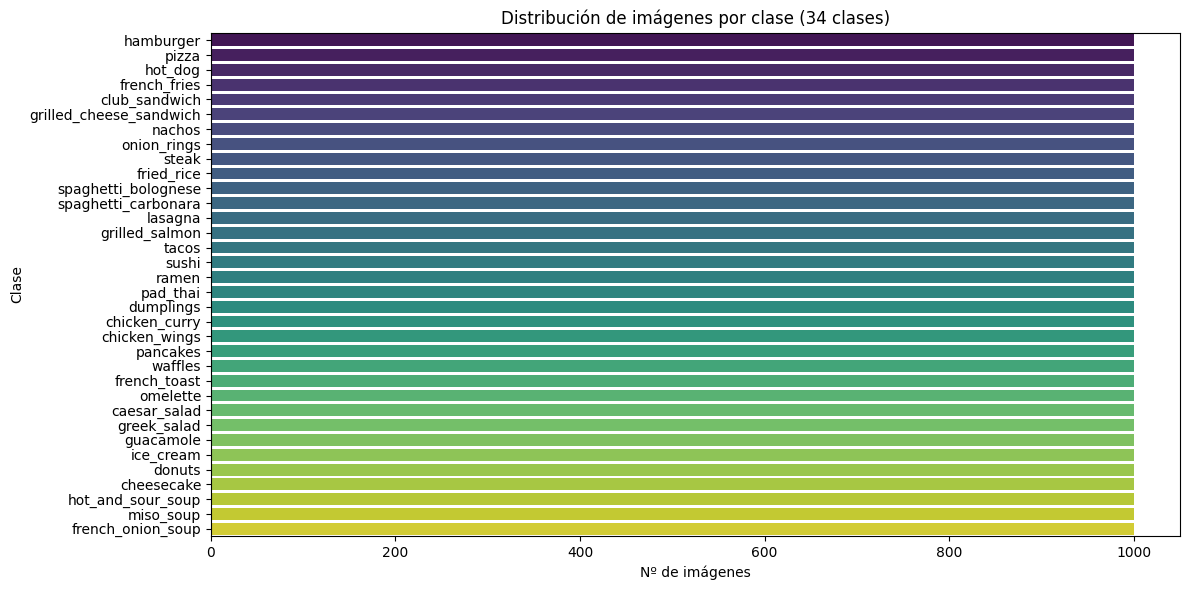

Food-101 suele traer 1000 imágenes por clase (balanceado).
Total filtrado: 34,000 imágenes en 34 clases


In [8]:
# Distribucion de clases en el conjunto completo filtrado
conteo = Counter(class_to_idx[idx_de_clase_full_a_nombre[full.samples[i][1]]] for i in indices)
conteo = {CLASSES[k]: v for k, v in sorted(conteo.items())}

plt.figure(figsize=(12, 6))
sns.barplot(x=list(conteo.values()), y=list(conteo.keys()), palette="viridis")
plt.title("Distribución de imágenes por clase (34 clases)")
plt.xlabel("Nº de imágenes"); plt.ylabel("Clase")
plt.tight_layout(); plt.show()

print("Food-101 suele traer 1000 imágenes por clase (balanceado).")
print(f"Total filtrado: {sum(conteo.values()):,} imágenes en {len(conteo)} clases")

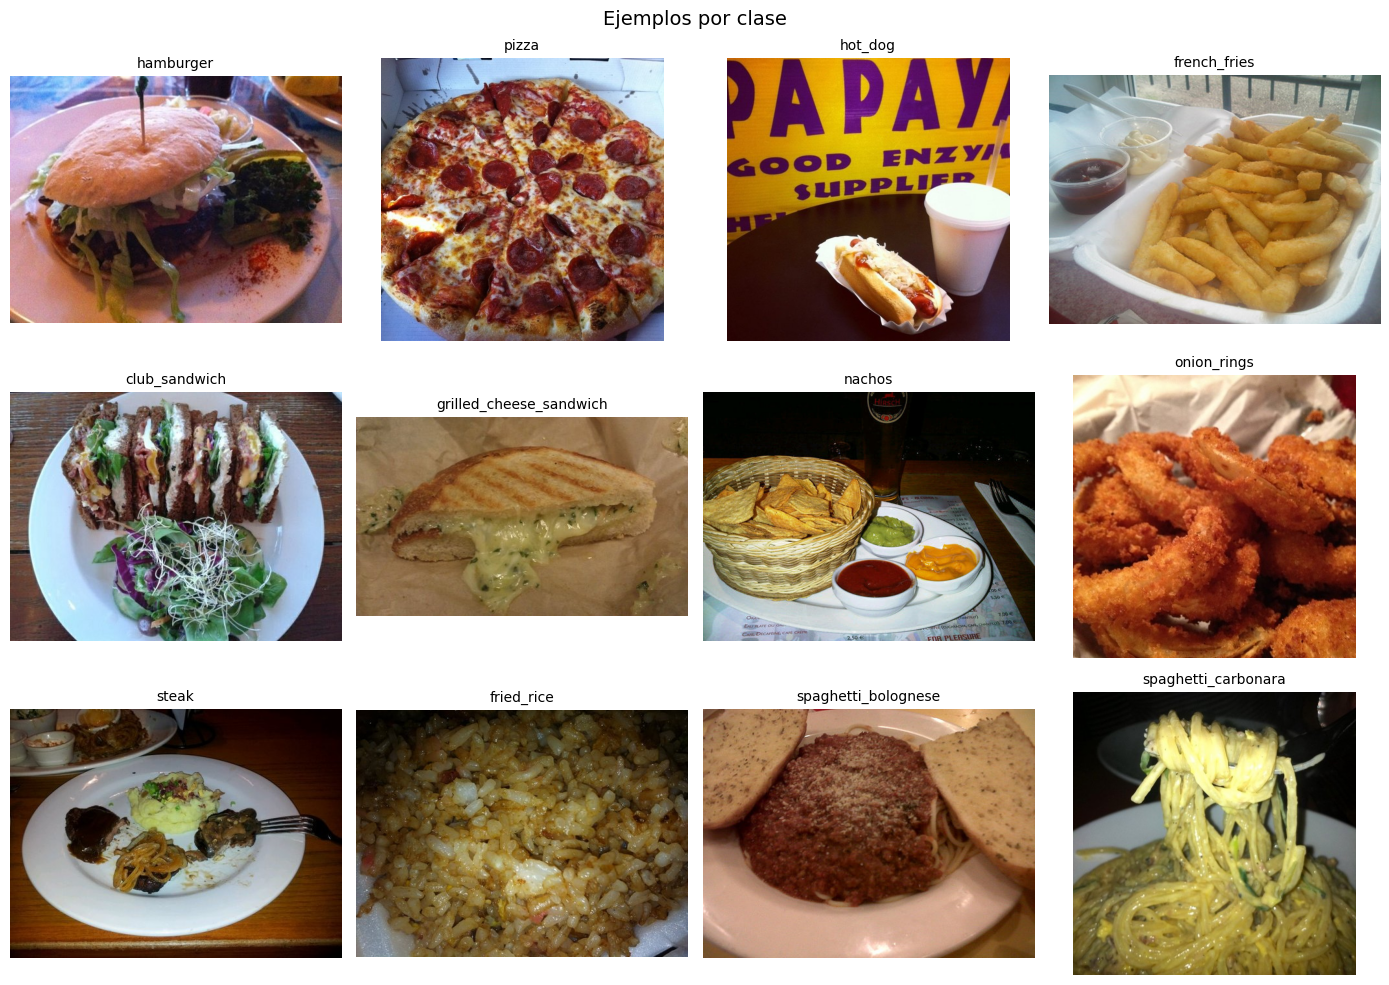

In [9]:
# Mostrar un ejemplo de cada una de las primeras 12 clases
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, clase in zip(axes.ravel(), CLASSES[:12]):
    # primera imagen de esa clase
    for i in indices:
        path, y = full.samples[i]
        if idx_de_clase_full_a_nombre[y] == clase:
            ax.imshow(Image.open(path).convert("RGB"))
            ax.set_title(clase, fontsize=10); ax.axis("off")
            break
plt.suptitle("Ejemplos por clase", fontsize=14)
plt.tight_layout(); plt.show()

## 7. Modelo — EfficientNet-B0 con transfer learning

Usamos **EfficientNet-B0** preentrenado en ImageNet y reemplazamos la capa final por una de 34 salidas. Estrategia: entrenar toda la red con un learning rate pequeño en el backbone y mayor en la cabeza (*fine-tuning*).

**Por qué EfficientNet-B0:** buen balance entre precisión y coste computacional (~4.05M parámetros en esta configuración), entrena rápido en una GPU de Kaggle y es un estándar bien documentado para clasificación de imágenes. EfficientNet introduce el *compound scaling*, que escala de forma equilibrada la profundidad, el ancho y la resolución de la red, logrando alta precisión con menos parámetros que arquitecturas previas.

**Modificación respecto al modelo original:** se mantiene el *backbone* convolucional preentrenado y solo se sustituye el clasificador final (de 1000 clases de ImageNet a 34 clases de comida).

**Referencia:** Tan, M., & Le, Q. (2019). *EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks*. Proceedings of the 36th International Conference on Machine Learning (ICML), PMLR 97:6105-6114. arXiv:1905.11946.

In [10]:
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
# Reemplazar el clasificador final (1280 -> 34)
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
model = model.to(DEVICE)

total = sum(p.numel() for p in model.parameters())
print(f"Modelo: EfficientNet-B0 | parámetros: {total:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 143MB/s] 


Modelo: EfficientNet-B0 | parámetros: 4,051,102


## 8. Entrenamiento

- **Pérdida:** CrossEntropyLoss (clasificación multiclase).
- **Optimizador:** AdamW con lr diferenciado (backbone vs cabeza).
- **Scheduler:** CosineAnnealing para bajar el lr suavemente.
- **AMP (mixed precision):** acelera y ahorra memoria en GPU.
- Guardamos el mejor modelo por F1 de validación.

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {"params": model.features.parameters(),   "lr": LR * 0.1},
    {"params": model.classifier.parameters(), "lr": LR},
], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    tot_loss, preds_all, labels_all = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            if train:
                optimizer.zero_grad()
            with torch.autocast(DEVICE, enabled=(DEVICE == "cuda")):
                out = model(x)
                loss = criterion(out, y)
            if train:
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
            tot_loss += loss.item() * x.size(0)
            preds_all.extend(out.argmax(1).cpu().numpy())
            labels_all.extend(y.cpu().numpy())
    n = len(loader.dataset)
    acc = accuracy_score(labels_all, preds_all)
    f1  = f1_score(labels_all, preds_all, average="macro")
    return tot_loss / n, acc, f1

/tmp/ipykernel_23/869449624.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))


In [12]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "train_f1": [], "val_f1": []}
best_f1 = 0.0
t0 = time.time()

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc, tr_f1 = run_epoch(train_loader, train=True)
    va_loss, va_acc, va_f1 = run_epoch(val_loader,   train=False)
    scheduler.step()

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
    history["train_f1"].append(tr_f1);     history["val_f1"].append(va_f1)

    if va_f1 > best_f1:
        best_f1 = va_f1
        torch.save(model.state_dict(), "best_model.pt")

    print(f"Epoch {epoch:2d}/{EPOCHS} | "
          f"train loss {tr_loss:.3f} acc {tr_acc:.3f} f1 {tr_f1:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} f1 {va_f1:.3f}")

print(f"\nTiempo total: {(time.time()-t0)/60:.1f} min | mejor val F1: {best_f1:.3f}")

Epoch  1/8 | train loss 1.302 acc 0.652 f1 0.652 | val loss 0.638 acc 0.818 f1 0.818
Epoch  2/8 | train loss 0.613 acc 0.822 f1 0.821 | val loss 0.521 acc 0.850 f1 0.850
Epoch  3/8 | train loss 0.450 acc 0.865 f1 0.865 | val loss 0.474 acc 0.869 f1 0.869
Epoch  4/8 | train loss 0.352 acc 0.894 f1 0.894 | val loss 0.463 acc 0.873 f1 0.874
Epoch  5/8 | train loss 0.282 acc 0.916 f1 0.916 | val loss 0.455 acc 0.878 f1 0.878
Epoch  6/8 | train loss 0.233 acc 0.929 f1 0.929 | val loss 0.450 acc 0.880 f1 0.881
Epoch  7/8 | train loss 0.212 acc 0.937 f1 0.937 | val loss 0.445 acc 0.882 f1 0.882
Epoch  8/8 | train loss 0.191 acc 0.942 f1 0.942 | val loss 0.442 acc 0.882 f1 0.882

Tiempo total: 37.6 min | mejor val F1: 0.882


## 9. Curvas de aprendizaje

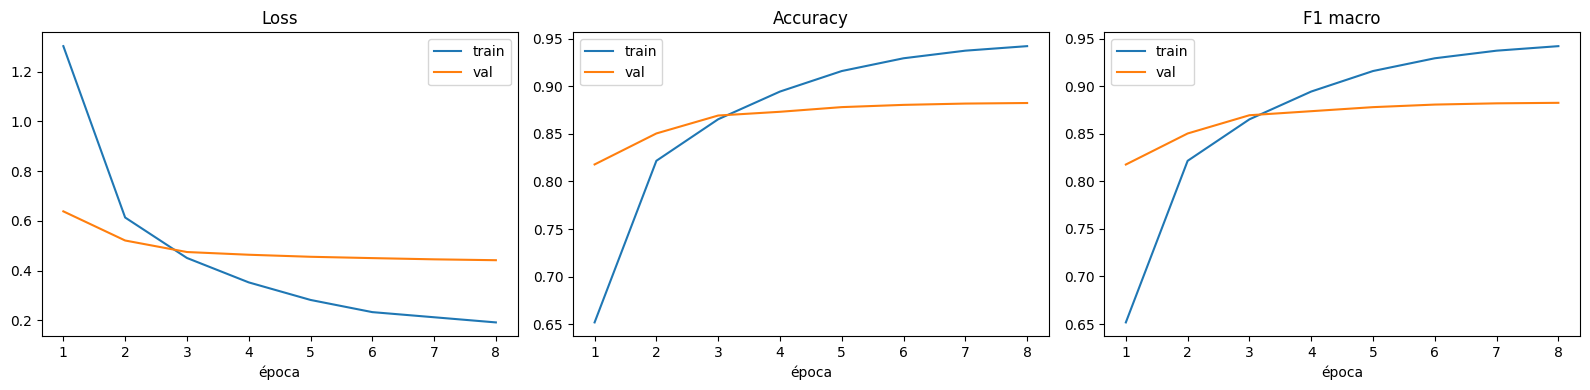

In [13]:
ep = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ep, history["train_loss"], label="train"); axes[0].plot(ep, history["val_loss"], label="val")
axes[0].set_title("Loss"); axes[0].set_xlabel("época"); axes[0].legend()
axes[1].plot(ep, history["train_acc"], label="train"); axes[1].plot(ep, history["val_acc"], label="val")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("época"); axes[1].legend()
axes[2].plot(ep, history["train_f1"], label="train"); axes[2].plot(ep, history["val_f1"], label="val")
axes[2].set_title("F1 macro"); axes[2].set_xlabel("época"); axes[2].legend()
plt.tight_layout(); plt.show()

### Análisis del entrenamiento

El modelo converge de forma estable a lo largo de las 8 épocas (Tesla T4, 37.6 min):

- El **F1 de validación** sube de 0.818 (época 1) a 0.882 (época 8) y se estabiliza en las últimas épocas, señal de convergencia.
- A partir de la época 5 aparece un **sobreajuste leve**: el F1 de entrenamiento sigue creciendo (0.916 hacia 0.942) mientras el de validación se estanca en ~0.88 y la *validation loss* deja de bajar (0.455 hacia 0.442). La brecha final train/val (0.942 vs 0.882, ~6 puntos) es moderada y esperable en *fine-tuning*.
- No hay subajuste: ambas métricas alcanzan valores altos. El *data augmentation* (flip, rotación, color jitter) y el *weight decay* contienen el sobreajuste; con más épocas probablemente crecería, por lo que detenerse en 8 y conservar el mejor modelo por F1 de validación es una decisión razonable.

## 10. Evaluación en test

Cargamos el mejor modelo y evaluamos sobre el conjunto de test (no visto en entrenamiento).

In [14]:
model.load_state_dict(torch.load("best_model.pt"))
model.eval()

preds_all, labels_all = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(DEVICE)
        out = model(x)
        preds_all.extend(out.argmax(1).cpu().numpy())
        labels_all.extend(y.numpy())

print(f"Test accuracy : {accuracy_score(labels_all, preds_all):.4f}")
print(f"Test F1 macro : {f1_score(labels_all, preds_all, average='macro'):.4f}\n")
print(classification_report(labels_all, preds_all, target_names=CLASSES, digits=3))

Test accuracy : 0.8800
Test F1 macro : 0.8800

                         precision    recall  f1-score   support

              hamburger      0.879     0.873     0.876       150
                  pizza      0.903     0.933     0.918       150
                hot_dog      0.866     0.860     0.863       150
           french_fries      0.903     0.933     0.918       150
          club_sandwich      0.891     0.820     0.854       150
grilled_cheese_sandwich      0.806     0.833     0.820       150
                 nachos      0.832     0.827     0.829       150
            onion_rings      0.953     0.940     0.946       150
                  steak      0.870     0.847     0.858       150
             fried_rice      0.915     0.867     0.890       150
    spaghetti_bolognese      0.898     0.940     0.919       150
    spaghetti_carbonara      0.951     0.913     0.932       150
                lasagna      0.838     0.760     0.797       150
         grilled_salmon      0.850     0.8

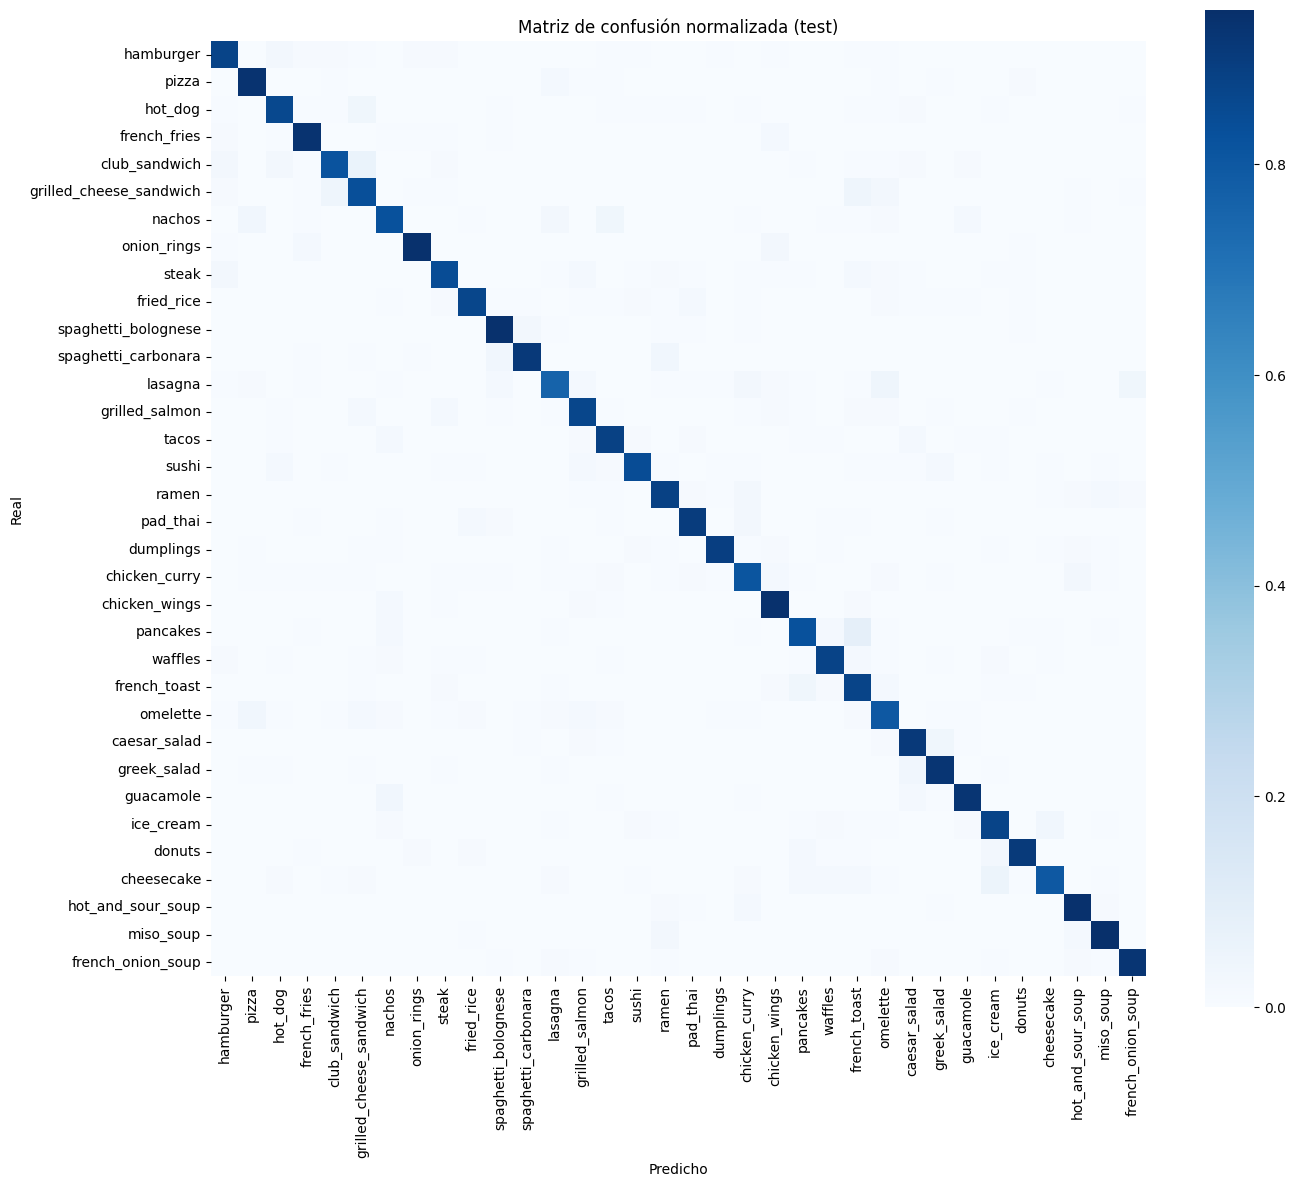

In [15]:
cm = confusion_matrix(labels_all, preds_all, normalize="true")
plt.figure(figsize=(14, 12))
sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues", square=True, cbar=True)
plt.title("Matriz de confusión normalizada (test)")
plt.xlabel("Predicho"); plt.ylabel("Real")
plt.xticks(rotation=90); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

### Análisis de resultados en test

El modelo alcanza **88.0% de accuracy y 0.880 de F1 macro** sobre 5.100 imágenes de test no vistas. Que accuracy y F1 macro coincidan refleja que el dataset está balanceado (150 imágenes por clase en test).

**Mejores clases:** `onion_rings` (F1 0.946), `miso_soup` (0.934), `spaghetti_carbonara` (0.932), `dumplings` (0.924) y `pizza` / `french_fries` (0.918). Son platos con forma, color o textura muy distintivos.

**Peores clases:** `omelette` (0.782), `lasagna` (0.797), `french_toast` (0.806), `chicken_curry` (0.813) y `grilled_cheese_sandwich` (0.820). Las confusiones tienen sentido visual: la lasaña se parece a otras pastas al horno (spaghetti bolognese), el omelette a otros platos de huevo, y french toast a pancakes/waffles. La matriz de confusión concentra los errores precisamente entre estos platos visualmente cercanos, no entre categorías dispares.

## 11. Tabla nutricional — USDA FoodData Central

La red clasifica el plato; la información nutricional (macros **por 100 g**) proviene de la fuente oficial: [USDA FoodData Central](https://fdc.nal.usda.gov/).

Los valores de abajo (`NUTRICION`) ya fueron **obtenidos de la API de USDA** y quedan cacheados en el notebook, de modo que corre con o sin internet. La celda siguiente incluye además la función `consultar_usda()` por si se quiere **refrescar en vivo** con una API key (gratis en https://fdc.nal.usda.gov/api-key-signup).

> Nota: son valores de referencia por 100 g del alimento más representativo encontrado en USDA; los platos preparados varían según la receta.

In [16]:
# === Valores nutricionales por 100 g, obtenidos de la API de USDA FoodData Central ===
# (cacheados: el notebook corre sin internet. Para refrescar en vivo, ver la celda siguiente.)
NUTRICION = {
    "hamburger":               {"kcal": 263,  "prot": 13.3, "grasa": 10.2, "carb": 29.6, "usda_desc": "Hamburger (McDonalds)"},
    "pizza":                   {"kcal": 230,  "prot": 16.9, "grasa": 14.7, "carb": 7.6,  "usda_desc": "Cheese pizza (topping)"},
    "hot_dog":                 {"kcal": 233,  "prot": 19.6, "grasa": 13.7, "carb": 7.7,  "usda_desc": "Hot dog"},
    "french_fries":            {"kcal": 290,  "prot": 3.3,  "grasa": 13.2, "carb": 39.5, "usda_desc": "French fries"},
    "club_sandwich":           {"kcal": 220,  "prot": 16.0, "grasa": 7.7,  "carb": 21.4, "usda_desc": "Club sandwich on wheat"},
    "grilled_cheese_sandwich": {"kcal": 343,  "prot": 11.0, "grasa": 20.8, "carb": 28.1, "usda_desc": "Grilled cheese sandwich"},
    "nachos":                  {"kcal": 242,  "prot": 11.2, "grasa": 13.3, "carb": 19.9, "usda_desc": "Nachos, chicken"},
    "onion_rings":             {"kcal": 385,  "prot": 5.3,  "grasa": 22.2, "carb": 41.0, "usda_desc": "Onion rings"},
    "steak":                   {"kcal": 326,  "prot": 18.3, "grasa": 27.6, "carb": 0.0,  "usda_desc": "Beef steak"},
    "fried_rice":              {"kcal": 174,  "prot": 3.8,  "grasa": 3.2,  "carb": 32.5, "usda_desc": "Rice, fried"},
    "spaghetti_bolognese":     {"kcal": 90,   "prot": 5.9,  "grasa": 4.4,  "carb": 6.5,  "usda_desc": "Spaghetti sauce with meat"},
    "spaghetti_carbonara":     {"kcal": 157,  "prot": 6.5,  "grasa": 6.8,  "carb": 17.0, "usda_desc": "Pasta carbonara (aprox.)"},
    "lasagna":                 {"kcal": 139,  "prot": 7.5,  "grasa": 5.0,  "carb": 16.2, "usda_desc": "Lasagna with meat"},
    "grilled_salmon":          {"kcal": 189,  "prot": 12.0, "grasa": 10.4, "carb": 11.8, "usda_desc": "Salmon, cooked"},
    "tacos":                   {"kcal": 181,  "prot": 13.0, "grasa": 11.3, "carb": 6.4,  "usda_desc": "Beef taco"},
    "sushi":                   {"kcal": 94,   "prot": 2.9,  "grasa": 0.7,  "carb": 18.4, "usda_desc": "Sushi, NFS"},
    "ramen":                   {"kcal": 66,   "prot": 1.5,  "grasa": 2.6,  "carb": 9.0,  "usda_desc": "Ramen noodle soup"},
    "pad_thai":                {"kcal": 154,  "prot": 8.1,  "grasa": 7.5,  "carb": 14.4, "usda_desc": "Pad Thai with chicken"},
    "dumplings":               {"kcal": 125,  "prot": 3.5,  "grasa": 3.4,  "carb": 20.5, "usda_desc": "Dumpling"},
    "chicken_curry":           {"kcal": 107,  "prot": 6.5,  "grasa": 6.5,  "carb": 6.5,  "usda_desc": "Chicken curry"},
    "chicken_wings":           {"kcal": 247,  "prot": 22.6, "grasa": 16.7, "carb": 0.0,  "usda_desc": "Chicken wing"},
    "pancakes":                {"kcal": 227,  "prot": 6.4,  "grasa": 9.7,  "carb": 28.3, "usda_desc": "Pancakes (aprox.)"},
    "waffles":                 {"kcal": 291,  "prot": 7.9,  "grasa": 14.1, "carb": 32.9, "usda_desc": "Waffle (aprox.)"},
    "french_toast":            {"kcal": 278,  "prot": 7.5,  "grasa": 9.2,  "carb": 40.6, "usda_desc": "French toast"},
    "omelette":                {"kcal": 154,  "prot": 10.6, "grasa": 11.7, "carb": 0.6,  "usda_desc": "Omelet, egg (aprox.)"},
    "caesar_salad":            {"kcal": 77,   "prot": 4.0,  "grasa": 3.4,  "carb": 7.5,  "usda_desc": "Caesar salad, no dressing"},
    "greek_salad":             {"kcal": 48,   "prot": 2.8,  "grasa": 2.3,  "carb": 4.3,  "usda_desc": "Greek salad, no dressing"},
    "guacamole":               {"kcal": 155,  "prot": 1.9,  "grasa": 14.2, "carb": 8.4,  "usda_desc": "Guacamole"},
    "ice_cream":               {"kcal": 207,  "prot": 3.5,  "grasa": 11.0, "carb": 23.6, "usda_desc": "Ice cream, vanilla"},
    "donuts":                  {"kcal": 417,  "prot": 4.5,  "grasa": 19.9, "carb": 57.4, "usda_desc": "Doughnut, cake-type"},
    "cheesecake":              {"kcal": 321,  "prot": 5.5,  "grasa": 22.5, "carb": 25.5, "usda_desc": "Cheesecake (aprox.)"},
    "hot_and_sour_soup":       {"kcal": 39,   "prot": 2.6,  "grasa": 1.2,  "carb": 4.3,  "usda_desc": "Soup, hot and sour"},
    "miso_soup":               {"kcal": 24,   "prot": 2.2,  "grasa": 0.8,  "carb": 2.3,  "usda_desc": "Soup, miso"},
    "french_onion_soup":       {"kcal": 108,  "prot": 5.5,  "grasa": 4.5,  "carb": 11.8, "usda_desc": "Soup, French onion"},
}

nutricion_df = pd.DataFrame(NUTRICION).T
nutricion_df

,kcal,prot,grasa,carb,usda_desc
hamburger,263,13.3,10.2,29.6,Hamburger (McDonalds)
pizza,230,16.9,14.7,7.6,Cheese pizza (topping)
hot_dog,233,19.6,13.7,7.7,Hot dog
french_fries,290,3.3,13.2,39.5,French fries
club_sandwich,220,16.0,7.7,21.4,Club sandwich on wheat
grilled_cheese_sandwich,343,11.0,20.8,28.1,Grilled cheese sandwich
nachos,242,11.2,13.3,19.9,"Nachos, chicken"
onion_rings,385,5.3,22.2,41.0,Onion rings
steak,326,18.3,27.6,0.0,Beef steak
fried_rice,174,3.8,3.2,32.5,"Rice, fried"


In [17]:
def info_nutricional(clase):
    datos = NUTRICION.get(clase)
    if not datos or datos.get("kcal") is None:
        return f"{clase}: (sin datos nutricionales)"
    return (f"{clase} (por 100 g, fuente USDA): {datos['kcal']} kcal | "
            f"{datos['prot']} g proteína | {datos['grasa']} g grasa | {datos['carb']} g carbs")

print(info_nutricional("pizza"))
print(info_nutricional("sushi"))
print(info_nutricional("hamburger"))

pizza (por 100 g, fuente USDA): 230 kcal | 16.9 g proteína | 14.7 g grasa | 7.6 g carbs
sushi (por 100 g, fuente USDA): 94 kcal | 2.9 g proteína | 0.7 g grasa | 18.4 g carbs
hamburger (por 100 g, fuente USDA): 263 kcal | 13.3 g proteína | 10.2 g grasa | 29.6 g carbs


### (Opcional) Refrescar los valores en vivo desde la API de USDA

Si quieres consultar la API en el momento (p. ej. para la sustentación), saca tu key gratis en https://fdc.nal.usda.gov/api-key-signup, pégala en `USDA_API_KEY` y ejecuta esta celda. Sobrescribe `NUTRICION` con los valores recién consultados.

In [18]:
import requests

USDA_API_KEY = "DEMO_KEY"   # <-- tu key (DEMO_KEY tiene límite bajo de consultas)

SEARCH_TERMS = {
    "hamburger": "hamburger", "pizza": "cheese pizza", "hot_dog": "hot dog",
    "french_fries": "french fries", "club_sandwich": "club sandwich",
    "grilled_cheese_sandwich": "grilled cheese sandwich", "nachos": "nachos",
    "onion_rings": "onion rings", "steak": "beef steak cooked", "fried_rice": "fried rice",
    "spaghetti_bolognese": "spaghetti with meat sauce", "spaghetti_carbonara": "spaghetti carbonara",
    "lasagna": "lasagna", "grilled_salmon": "salmon cooked", "tacos": "beef taco",
    "sushi": "sushi", "ramen": "ramen noodle soup", "pad_thai": "pad thai",
    "dumplings": "dumpling", "chicken_curry": "chicken curry", "chicken_wings": "chicken wing",
    "pancakes": "pancake", "waffles": "waffle", "french_toast": "french toast",
    "omelette": "omelet egg", "caesar_salad": "caesar salad", "greek_salad": "greek salad",
    "guacamole": "guacamole", "ice_cream": "ice cream vanilla", "donuts": "donut",
    "cheesecake": "cheesecake", "hot_and_sour_soup": "hot and sour soup",
    "miso_soup": "miso soup", "french_onion_soup": "french onion soup",
}
NUTR_IDS = {1008: "kcal", 1003: "prot", 1004: "grasa", 1005: "carb"}

def consultar_usda(term):
    body = {"query": term, "pageSize": 5,
            "dataType": ["Survey (FNDDS)", "SR Legacy", "Foundation"]}
    r = requests.post("https://api.nal.usda.gov/fdc/v1/foods/search",
                      params={"api_key": USDA_API_KEY}, json=body, timeout=30)
    r.raise_for_status()
    foods = r.json().get("foods", [])
    if not foods:
        return None
    palabras = set(term.lower().split())
    mejor = next((f for f in foods if palabras & set(f.get("description", "").lower().replace(",", " ").split())), foods[0])
    macros = {v: None for v in NUTR_IDS.values()}
    for n in mejor.get("foodNutrients", []):
        if n.get("nutrientId") in NUTR_IDS:
            macros[NUTR_IDS[n["nutrientId"]]] = round(n.get("value", 0), 1)
    macros["usda_desc"] = mejor.get("description", "")
    return macros

# Descomenta para refrescar en vivo las 34 clases:
# import time
# nuevos = {}
# for c in CLASSES:
#     try:
#         nuevos[c] = consultar_usda(SEARCH_TERMS[c]); print(c, nuevos[c])
#     except Exception as e:
#         print(c, 'error', e)
#     time.sleep(1.0)
# NUTRICION.update({k: v for k, v in nuevos.items() if v})
print("Celda de refresco lista. Pon tu API key y descomenta el bucle para usarla.")

Celda de refresco lista. Pon tu API key y descomenta el bucle para usarla.


## 12. Evaluación en datos externos (generalización)

Requisito del profesor: probar el modelo con imágenes **no vistas** (fotos tuyas o de internet). En Kaggle, sube tus fotos como un dataset propio o con *Upload* y ajusta `MIS_FOTOS`.

Fotos encontradas: 5


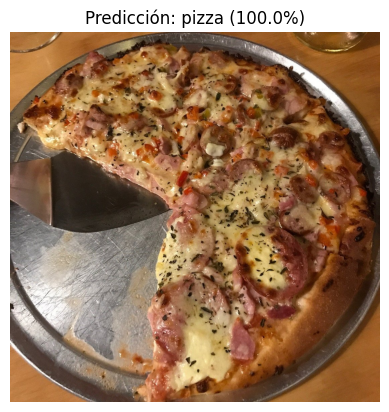

Top-k:
  pizza                100.0%
  lasagna                0.0%
  omelette               0.0%

pizza (por 100 g, fuente USDA): 230 kcal | 16.9 g proteína | 14.7 g grasa | 7.6 g carbs


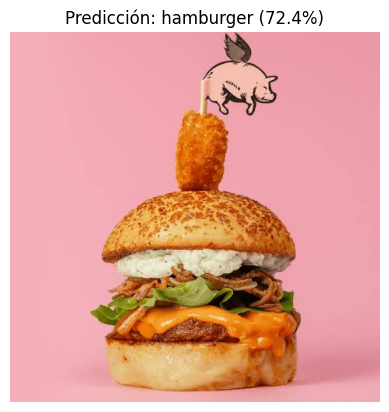

Top-k:
  hamburger             72.4%
  club_sandwich         22.5%
  grilled_cheese_sandwich   1.7%

hamburger (por 100 g, fuente USDA): 263 kcal | 13.3 g proteína | 10.2 g grasa | 29.6 g carbs


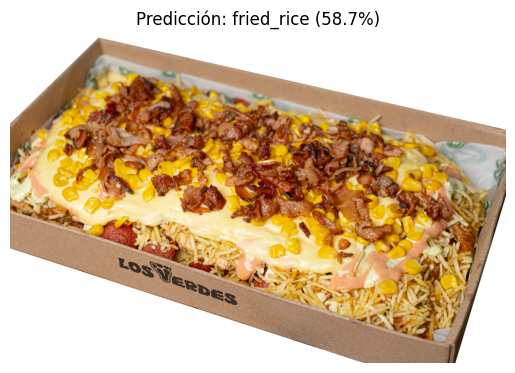

Top-k:
  fried_rice            58.7%
  hot_dog                9.9%
  donuts                 7.8%

fried_rice (por 100 g, fuente USDA): 174 kcal | 3.8 g proteína | 3.2 g grasa | 32.5 g carbs


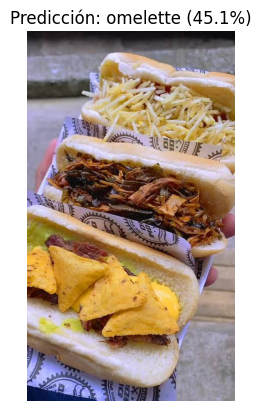

Top-k:
  omelette              45.1%
  hot_dog               17.1%
  ramen                  9.2%

omelette (por 100 g, fuente USDA): 154 kcal | 10.6 g proteína | 11.7 g grasa | 0.6 g carbs


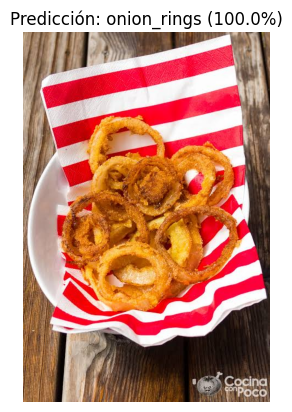

Top-k:
  onion_rings          100.0%
  hamburger              0.0%
  chicken_wings          0.0%

onion_rings (por 100 g, fuente USDA): 385 kcal | 5.3 g proteína | 22.2 g grasa | 41.0 g carbs
Sube tus fotos externas y llama a predecir(ruta) para probar la generalización.


In [19]:
def predecir(path_img, topk=3):
    img = Image.open(path_img).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x), dim=1)[0]
    top = torch.topk(probs, topk)
    plt.imshow(img); plt.axis("off")
    pred = CLASSES[top.indices[0].item()]
    plt.title(f"Predicción: {pred} ({top.values[0].item()*100:.1f}%)")
    plt.show()
    print("Top-k:")
    for p, i in zip(top.values, top.indices):
        print(f"  {CLASSES[i.item()]:20s} {p.item()*100:5.1f}%")
    print("\n" + info_nutricional(pred))
    return pred

MIS_FOTOS = "/kaggle/input/datasets/juanestebanorrego/fotoscomida/Fotos_comida"
exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
fotos = [p for p in Path(MIS_FOTOS).rglob("*") if p.suffix.lower() in exts]
print("Fotos encontradas:", len(fotos))
for f in sorted(fotos):
    predecir(f)

### Análisis de la generalización (datos externos)

Se probó el modelo con **5 fotografías externas** (ajenas a Food-101): pizza, hamburguesa, papas fritas, hot dog y aros de cebolla. Acertó **3 de 5 (60%)**, frente al 88% del test interno. Esta caída de ~28 puntos evidencia la **brecha de dominio** (*domain gap*): las imágenes externas difieren en iluminación, ángulo, encuadre y presentación respecto al dataset de entrenamiento.

- **Aciertos:** pizza (100%), aros de cebolla (100%) y hamburguesa (72%), todos platos visualmente claros y bien encuadrados.
- **Errores, ambos con baja confianza (no falsa seguridad):**
  - Unas *papas fritas cargadas* (con maíz, tocino y salsa) se predijeron como `fried_rice` (59%): la mezcla de piezas pequeñas doradas y granos de maíz se asemeja visualmente a un arroz frito.
  - Una foto con *varios hot dogs apilados* junto a papas y nachos se predijo como `omelette` (45%); al ser una imagen con múltiples alimentos a la vez (y no un único plato centrado como en el entrenamiento), el modelo se confunde, aunque `hot_dog` aparece segundo en el top-3.

**Conclusión del análisis:** el modelo generaliza bien a comidas visualmente distintivas y correctamente encuadradas, pero su desempeño se degrada ante platos compuestos, imágenes con varios alimentos o presentaciones atípicas. Es una limitación coherente con haber entrenado sobre un único dataset de imágenes de un solo plato por foto.

## 13. Conclusiones

- **Objetivos cumplidos.** Se construyó un clasificador de 34 platos de comida con *transfer learning* (EfficientNet-B0) que alcanza **88% de accuracy / 0.88 F1 macro** en test, y se vinculó cada predicción con su información nutricional de referencia obtenida de **USDA FoodData Central**. El objetivo general y los específicos (preparar datos, entrenar/optimizar, evaluar generalización + nutrición) se cumplieron.
- **Desempeño y sus límites.** El modelo clasifica muy bien platos visualmente distintivos y confunde sobre todo comidas parecidas entre sí (pastas al horno, platos de huevo, panes dulces). En datos externos el rendimiento baja a 60% por la brecha de dominio y por imágenes compuestas o mal encuadradas.
- **Interpretación.** Las métricas no se explican solas: los aciertos se concentran en clases distintivas y los errores en clases visualmente cercanas, tanto en test como en datos externos. Los fallos externos ocurrieron con baja confianza, lo que indica incertidumbre del modelo más que error rotundo.
- **Limitaciones.** Entrenamiento sobre un único dataset (un plato por imagen), sobreajuste leve a partir de la época 5, y la información nutricional es por 100 g del alimento de referencia (no estima la porción real de la foto).
- **Mejoras futuras.** Ampliar con imágenes de dominios variados, aplicar más regularización o *early stopping*, probar arquitecturas mayores (EfficientNet-B3), y estimar la porción/volumen para una estimación nutricional más precisa.